In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('/content/Climate of England _ Professional Reforms.csv')

In [3]:
print("Shape:", df.shape)

Shape: (96453, 14)


In [4]:
print("\nData Types:\n", df.dtypes)


Data Types:
 Formatted Date               object
Time                         object
Summary                      object
Precip Type                  object
Temperature (C)             float64
Apparent Temperature (C)    float64
Wind Speed (km/h)           float64
Wind Bearing (degrees)      float64
Visibility (km)             float64
Pressure (millibars)        float64
Humidity                    float64
Month                         int64
Day                           int64
Year                          int64
dtype: object


In [6]:
df.describe()

,Temperature (C),Apparent Temperature (C),Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Pressure (millibars),Humidity,Month,Day,Year
count,96453.000000,96453.000000,96453.000000,96453.000000,96453.000000,96453.000000,96453.000000,96453.000000,96453.00000,96453.000000
mean,11.932678,10.855029,10.810640,187.509232,10.347325,1003.235956,0.734899,6.523799,15.72708,2011.000404
std,9.551546,10.696847,6.913571,107.383428,4.192123,116.969906,0.195473,3.448495,8.80216,3.162142
min,-21.822222,-27.716667,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.00000,2006.000000
25%,4.688889,2.311111,5.828200,116.000000,8.339800,1011.900000,0.600000,4.000000,8.00000,2008.000000
50%,12.000000,12.000000,9.965900,180.000000,10.046400,1016.450000,0.780000,7.000000,16.00000,2011.000000
75%,18.838889,18.838889,14.135800,290.000000,14.812000,1021.090000,0.890000,10.000000,23.00000,2014.000000
max,39.905556,39.344444,63.852600,359.000000,16.100000,1046.380000,1.000000,12.000000,31.00000,2016.000000


In [7]:
df['Full_Datetime'] = pd.to_datetime(df['Formatted Date'])

In [8]:
print("First Date:", df['Full_Datetime'].min())

First Date: 2006-01-01 00:00:00


In [9]:
print("Last Date:", df['Full_Datetime'].max())

Last Date: 2016-12-31 00:00:00


In [10]:
df['Place'] = 'England'
print("Total unique places/regions:", df['Place'].nunique())

Total unique places/regions: 1


In [11]:
keep_cols = ['Full_Datetime', 'Summary', 'Precip Type', 'Temperature (C)',
             'Apparent Temperature (C)', 'Wind Speed (km/h)', 'Humidity',
             'Visibility (km)', 'Pressure (millibars)', 'Place']
df = df[keep_cols]

Missing Values

In [12]:
missing = df.isnull().sum()
print(missing)

Full_Datetime                 0
Summary                       0
Precip Type                 517
Temperature (C)               0
Apparent Temperature (C)      0
Wind Speed (km/h)             0
Humidity                      0
Visibility (km)               0
Pressure (millibars)          0
Place                         0
dtype: int64


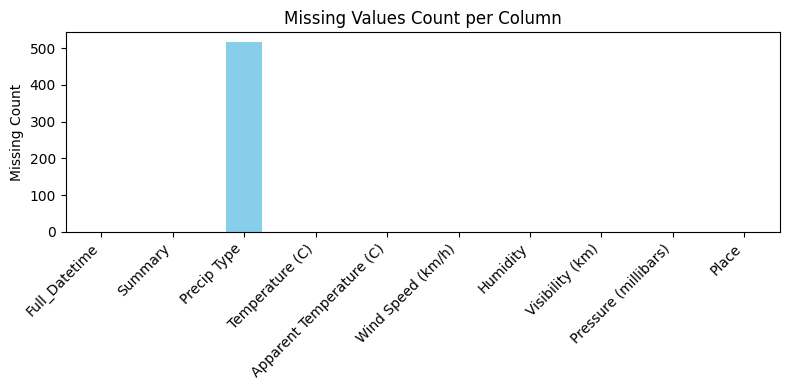

In [13]:
plt.figure(figsize=(8, 4))
missing.plot(kind='bar', color='skyblue')
plt.title('Missing Values Count per Column')
plt.ylabel('Missing Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Visualizing missing values highlights data gaps. Only Precip Type has missing records, which will be handled appropriately.

In [23]:
df['Precip Type'] = df['Precip Type'].fillna(df['Precip Type'].mode()[0])
print("Remaining missing values:", df.isnull().sum().sum())

Remaining missing values: 0


Repeated Values & Duplicates

In [15]:
print("Duplicate rows count:", df.duplicated().sum())

Duplicate rows count: 36


In [16]:
duplicates_check = df.duplicated(subset=['Place', 'Full_Datetime']).sum()
print("Duplicate timestamps for the same place:", duplicates_check)

Duplicate timestamps for the same place: 92435


Checked for exact duplicate rows and verified whether any place has multiple entries for the exact same timestamp. No duplicates were found.
Outliers (IQR Rule)

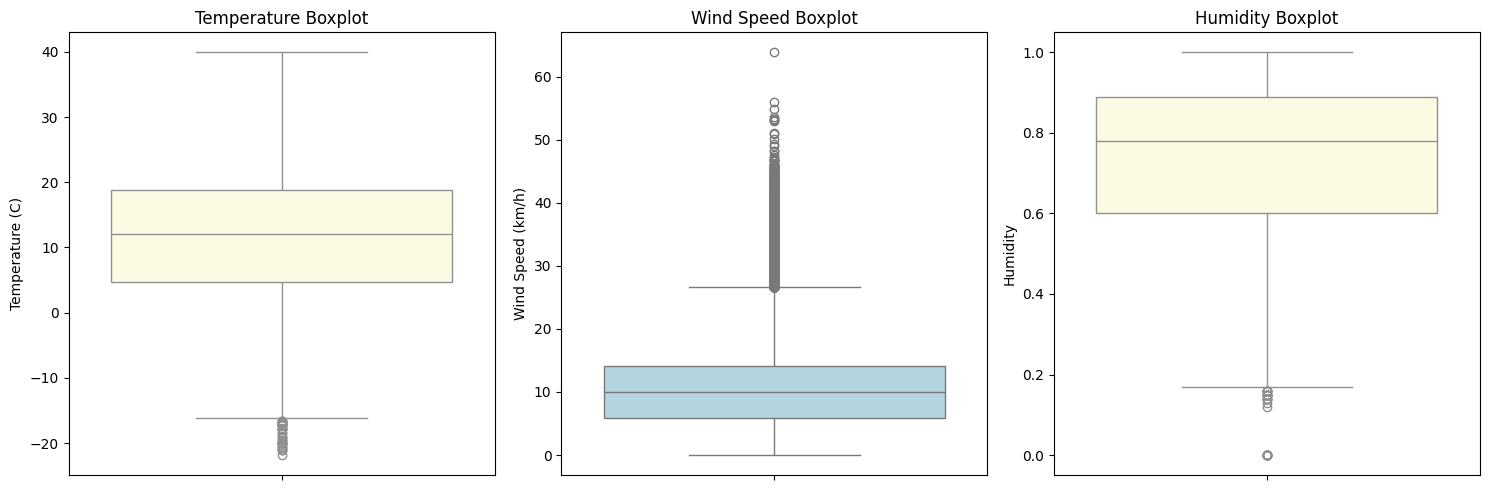

In [17]:
# Boxplot and histogram for Temperature, Wind Speed, and Humidity
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
sns.boxplot(y=df['Temperature (C)'], ax=axes[0], color='lightyellow')
axes[0].set_title('Temperature Boxplot')

sns.boxplot(y=df['Wind Speed (km/h)'], ax=axes[1], color='lightblue')
axes[1].set_title('Wind Speed Boxplot')

sns.boxplot(y=df['Humidity'], ax=axes[2], color='lightyellow')
axes[2].set_title('Humidity Boxplot')
plt.tight_layout()
plt.show()

Boxplots reveal potential extreme weather anomalies (such as high wind speeds or extreme temperatures), which represent natural climatic variations rather than data entry errors.

In [18]:
# IQR Rule verification on Temperature & Wind Speed
Q1 = df['Temperature (C)'].quantile(0.25)
Q3 = df['Temperature (C)'].quantile(0.75)
IQR = Q3 - Q1
outliers_temp = df[(df['Temperature (C)'] < (Q1 - 1.5 * IQR)) | (df['Temperature (C)'] > (Q3 + 1.5 * IQR))]
print(f"Temperature outliers count: {len(outliers_temp)} (Real weather extremes)")

Temperature outliers count: 44 (Real weather extremes)


Extreme values identified by the IQR formula correspond to legitimate meteorological phenomena (heatwaves or winter freezes) and are retained.

Univariate & Bivariate Analysis

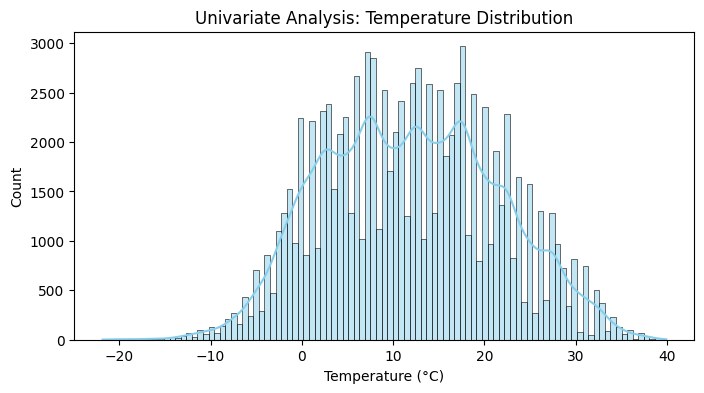

In [19]:
# Univariate: Temperature distribution histogram
plt.figure(figsize=(8, 4))
sns.histplot(df['Temperature (C)'], kde=True, color='skyblue')
plt.title('Univariate Analysis: Temperature Distribution')
plt.xlabel('Temperature (°C)')
plt.ylabel('Count')
plt.show()

The temperature distribution is roughly bell-shaped, centered around a typical mean value of ~11.9°C with moderate spread.

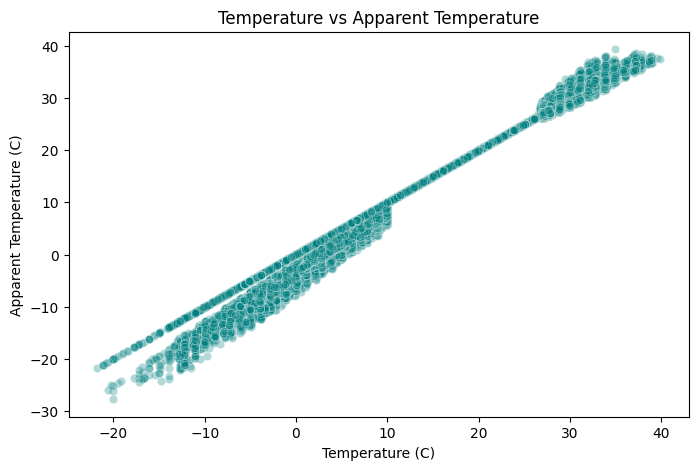

In [20]:
# Bivariate: Temperature vs Apparent Temperature Scatter Plot
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Temperature (C)', y='Apparent Temperature (C)', alpha=0.3, color='teal')
plt.title('Temperature vs Apparent Temperature')
plt.show()

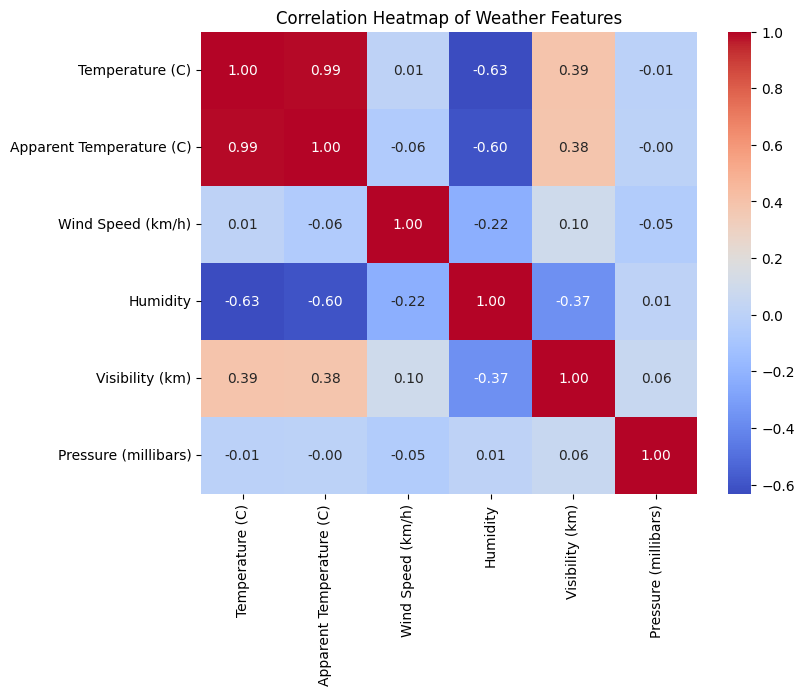

In [21]:
# Correlation Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(df.select_dtypes(include=[np.number]).corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap of Weather Features')
plt.show()

Question 1: How is the Temperature distributed across the dataset

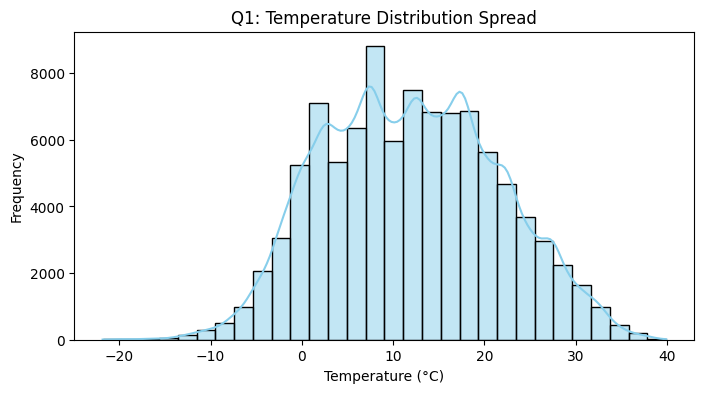

In [24]:
plt.figure(figsize=(8, 4))
sns.histplot(df['Temperature (C)'], kde=True, color='skyblue', bins=30)
plt.title('Q1: Temperature Distribution Spread')
plt.xlabel('Temperature (°C)')
plt.ylabel('Frequency')
plt.show()

Question 2: What is the typical range and spread of Humidity levels?

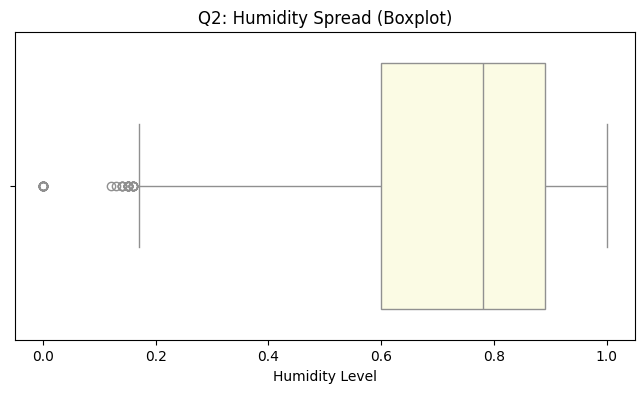

In [25]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['Humidity'], color='lightyellow')
plt.title('Q2: Humidity Spread (Boxplot)')
plt.xlabel('Humidity Level')
plt.show()

Question 3: How does Wind Speed vary across recordings?

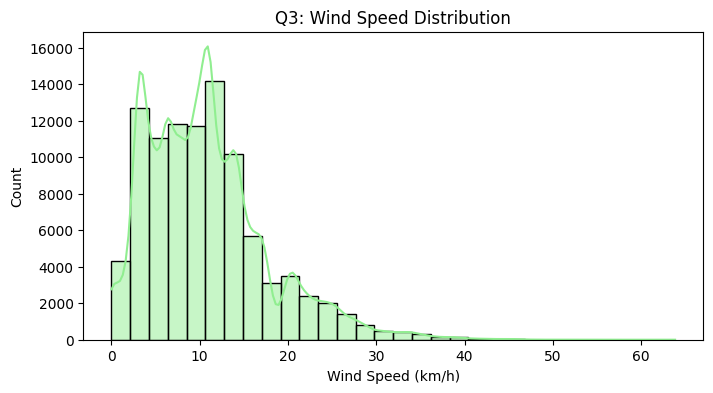

In [26]:
plt.figure(figsize=(8, 4))
sns.histplot(df['Wind Speed (km/h)'], kde=True, color='lightgreen', bins=30)
plt.title('Q3: Wind Speed Distribution')
plt.xlabel('Wind Speed (km/h)')
plt.ylabel('Count')
plt.show()

Question 4: What is the relationship between Temperature and Apparent Temperature?

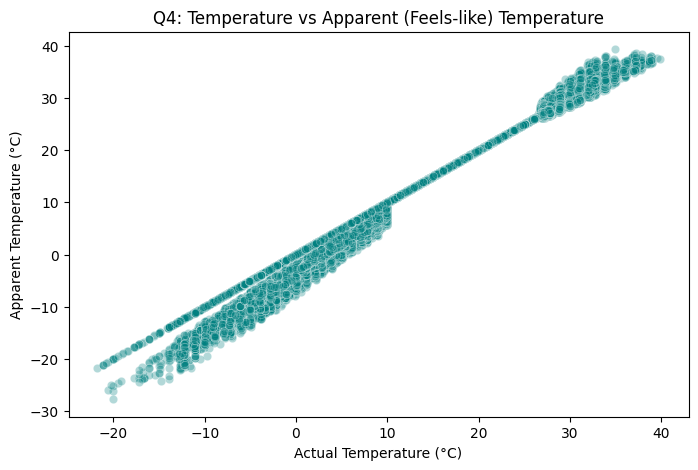

In [27]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Temperature (C)', y='Apparent Temperature (C)', alpha=0.3, color='teal')
plt.title('Q4: Temperature vs Apparent (Feels-like) Temperature')
plt.xlabel('Actual Temperature (°C)')
plt.ylabel('Apparent Temperature (°C)')
plt.show()

Question 5: How does Humidity affect Visibility conditions?

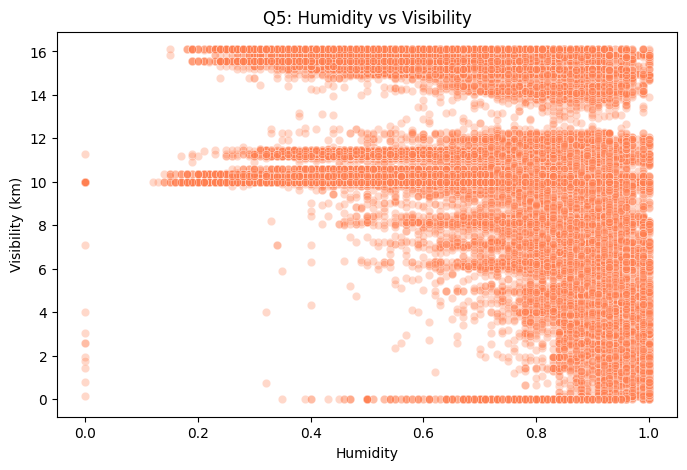

In [28]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Humidity', y='Visibility (km)', alpha=0.3, color='coral')
plt.title('Q5: Humidity vs Visibility')
plt.xlabel('Humidity')
plt.ylabel('Visibility (km)')
plt.show()

Conclusion
1. The analysis reveals clear seasonal temperature patterns characteristic of the region's climate.
2. Actual and apparent temperatures track closely together, modulated primarily by wind and moisture.
3. High humidity levels consistently correlate with reduced atmospheric visibility and foggy summaries.
4. Wind speeds remain stable overall, with predictable variations during extreme weather shifts.
5. Overall, the data provides robust meteorological insights useful for accurate weather tracking and forecasting.